# Mini Project — Customer Churn Prediction using Machine Learning

**Dataset:** Telco Customer Churn (Kaggle: `blastchar/telco-customer-churn`, original source IBM Sample Data Sets) — 7,043 customers × 21 attributes.

**Problem:** Predict whether a telecom customer will leave the company (*churn*) so the business can intervene with retention offers before the customer is lost.

**Workflow:**
1. Data loading & cleaning
2. Exploratory Data Analysis (EDA)
3. Feature engineering & encoding
4. Handling class imbalance (SMOTE)
5. Training 10 classification algorithms
6. Hyper-parameter tuning of the best model
7. Decision-threshold optimisation
8. Feature importance & business insights
9. Saving the final model and predicting for new customers

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, joblib, json
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay, precision_recall_curve)
sns.set_theme(style='whitegrid', palette='Set2')
RS = 42
import os; os.makedirs('results', exist_ok=True); os.makedirs('model', exist_ok=True)

## 1. Data loading & cleaning

In [2]:
df = pd.read_csv('data/Telco-Customer-Churn.csv')
print('Shape:', df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


`TotalCharges` is stored as text. Converting it to numbers reveals 11 blank values — all belong to customers with `tenure = 0` (joined this month, not yet billed), so they are filled with 0.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Blank TotalCharges:', df['TotalCharges'].isna().sum(), '| their tenure values:', df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop(columns='customerID')
print('Duplicates:', df.duplicated().sum(), '| Missing after cleaning:', df.isna().sum().sum())
df.describe()

Blank TotalCharges: 11 | their tenure values: [0]
Duplicates: 22 | Missing after cleaning: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


## 2. Exploratory Data Analysis

Churn rate: 26.54%  -> the classes are imbalanced (~73 : 27)


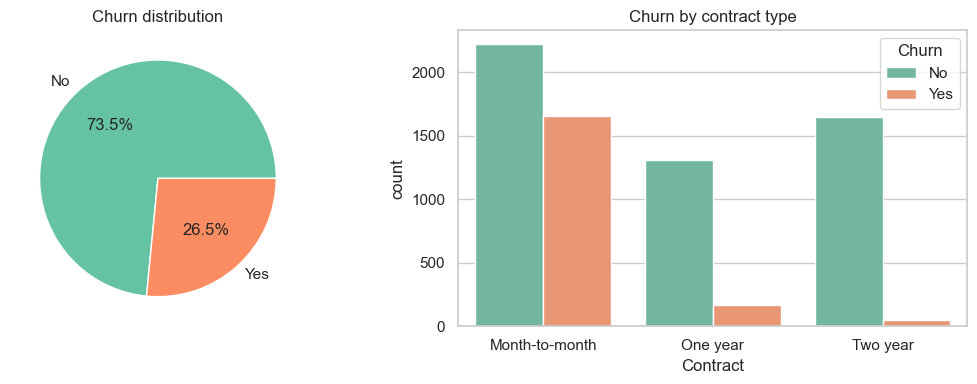

In [5]:
churn_rate = (df['Churn'] == 'Yes').mean()
print(f'Churn rate: {churn_rate:.2%}  -> the classes are imbalanced (~73 : 27)')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df['Churn'].value_counts().plot.pie(autopct='%1.1f%%', ax=ax[0], colors=['#66c2a5', '#fc8d62']); ax[0].set_ylabel(''); ax[0].set_title('Churn distribution')
sns.countplot(x='Contract', hue='Churn', data=df, ax=ax[1]); ax[1].set_title('Churn by contract type')
plt.tight_layout(); plt.savefig('results/fig1_churn_distribution.png', dpi=130); plt.show()

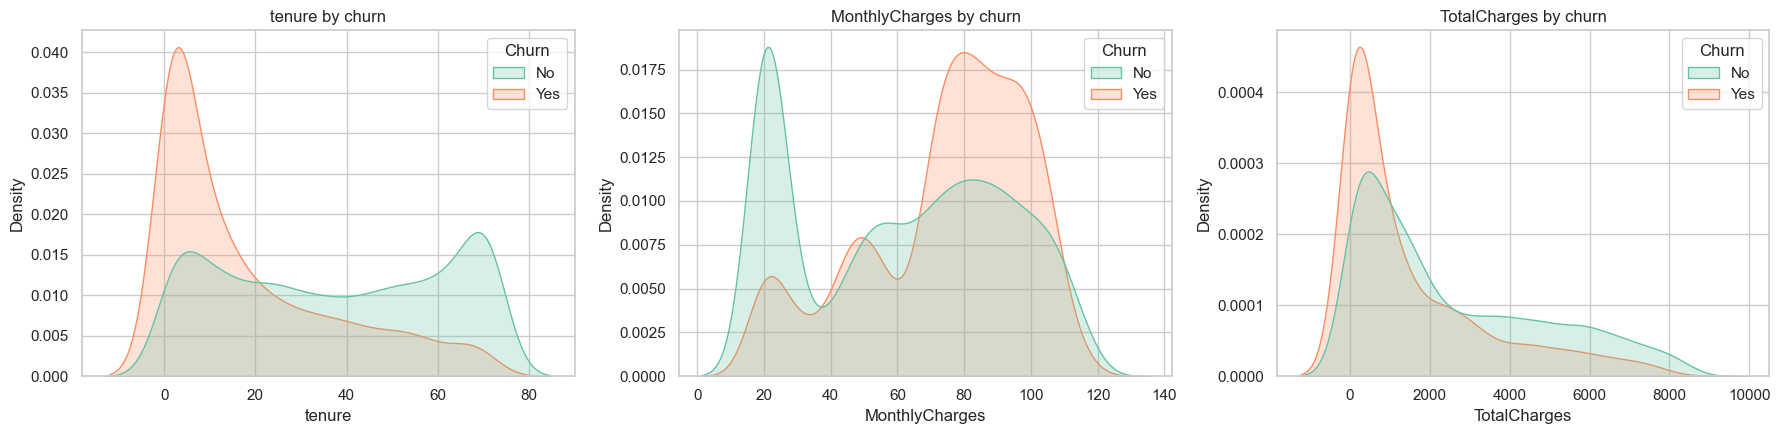

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, col in zip(ax, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.kdeplot(data=df, x=col, hue='Churn', fill=True, common_norm=False, ax=a); a.set_title(f'{col} by churn')
plt.tight_layout(); plt.savefig('results/fig2_numeric_distributions.png', dpi=130); plt.show()

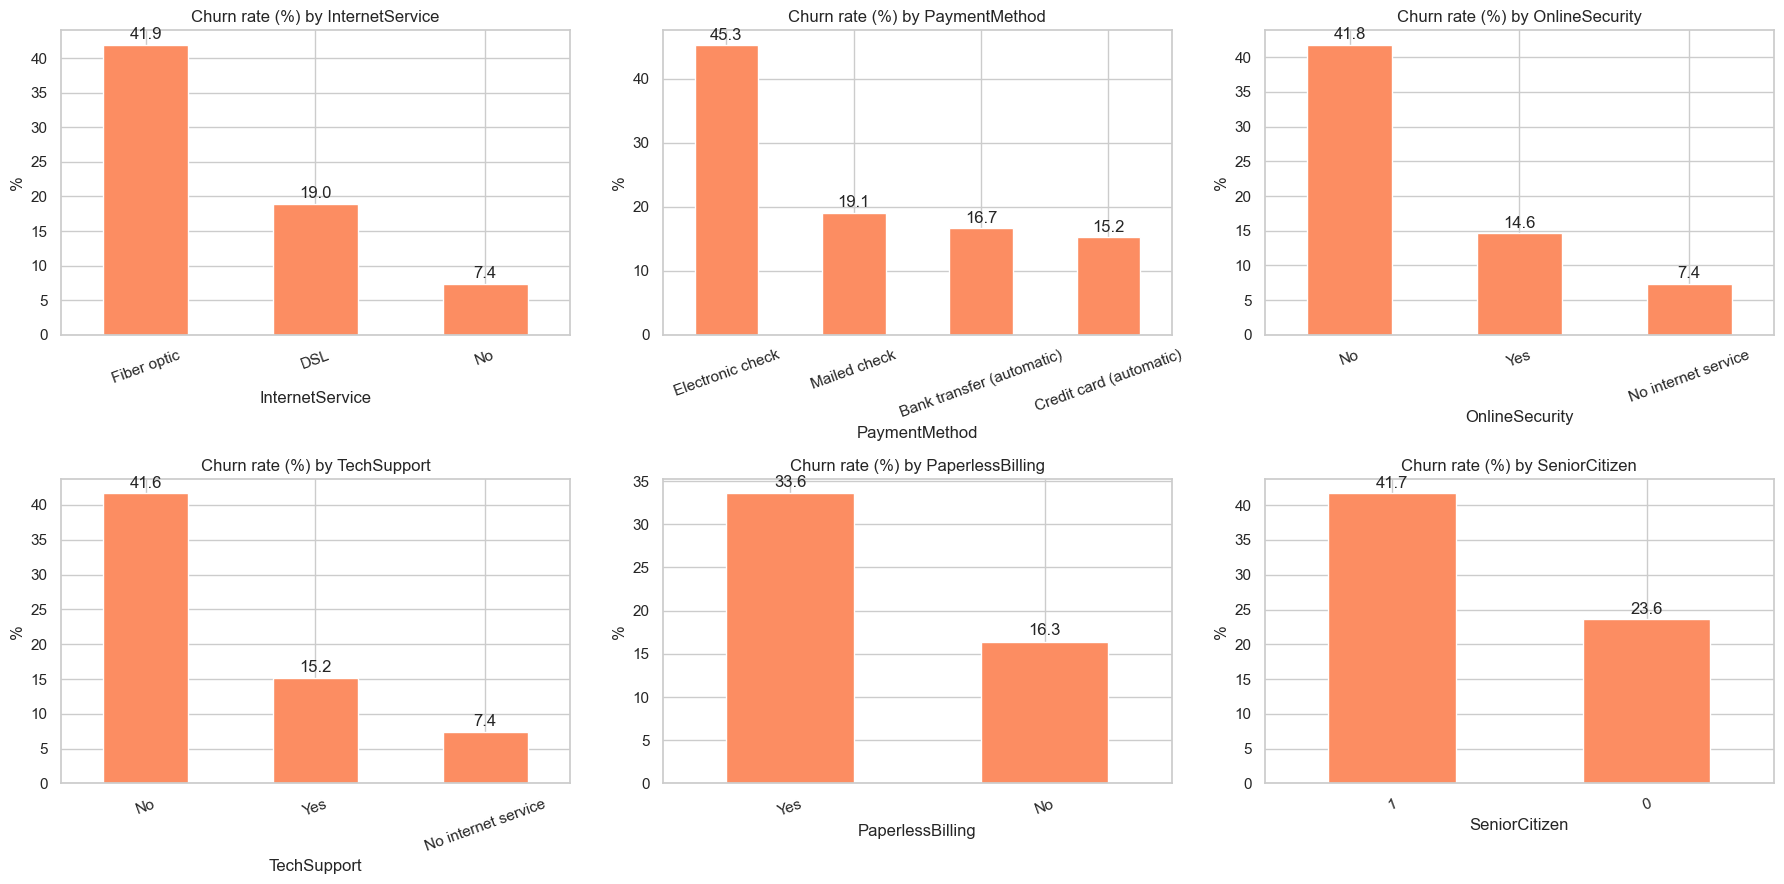

In [7]:
cats = ['InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'PaperlessBilling', 'SeniorCitizen']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for a, col in zip(axes.ravel(), cats):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values(ascending=False)
    rate.plot.bar(ax=a, color='#fc8d62'); a.set_title(f'Churn rate (%) by {col}'); a.set_ylabel('%'); a.tick_params(axis='x', rotation=20)
    for i, v in enumerate(rate): a.text(i, v + 0.8, f'{v:.1f}', ha='center')
plt.tight_layout(); plt.savefig('results/fig3_churn_rate_by_category.png', dpi=130); plt.show()

In [8]:
summary = {}
for col in ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'SeniorCitizen', 'Partner', 'Dependents']:
    summary[col] = (df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)).round(1).to_dict()
json.dump(summary, open('results/churn_rate_by_category.json', 'w'), indent=1)
pd.DataFrame([(k, kk, vv) for k, v in summary.items() for kk, vv in v.items()], columns=['Feature', 'Value', 'Churn rate %'])

,Feature,Value,Churn rate %
0,Contract,Month-to-month,42.7
1,Contract,One year,11.3
2,Contract,Two year,2.8
3,InternetService,DSL,19.0
4,InternetService,Fiber optic,41.9
5,InternetService,No,7.4
6,PaymentMethod,Bank transfer (automatic),16.7
7,PaymentMethod,Credit card (automatic),15.2
8,PaymentMethod,Electronic check,45.3
9,PaymentMethod,Mailed check,19.1


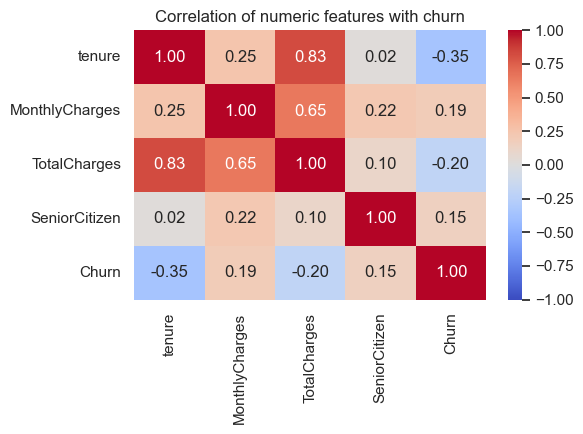

In [9]:
num = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].assign(Churn=(df['Churn'] == 'Yes').astype(int))
plt.figure(figsize=(6, 4.5)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of numeric features with churn'); plt.tight_layout(); plt.savefig('results/fig4_correlation.png', dpi=130); plt.show()

## 3. Feature engineering & encoding
Two new features are added:
- `NumServices` — how many optional add-on services the customer subscribes to.
- `AvgMonthlySpend` — `TotalCharges / tenure`, a smoother view of what the customer really pays.

In [10]:
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['NumServices'] = (df[addons] == 'Yes').sum(axis=1)
df['AvgMonthlySpend'] = np.where(df['tenure'] > 0, df['TotalCharges'] / df['tenure'].replace(0, 1), df['MonthlyCharges'])

y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns='Churn')
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'AvgMonthlySpend', 'SeniorCitizen']
cat_cols = [c for c in X.columns if c not in num_cols]
preprocess = ColumnTransformer([('num', StandardScaler(), num_cols),
                                ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols)])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Encoded feature count:', preprocess.fit(X_train).transform(X_train).shape[1])

Train: (5634, 21) | Test: (1409, 21)
Encoded feature count: 42


## 4 & 5. Train 10 algorithms (with SMOTE to balance the training folds)
SMOTE is applied **inside** the pipeline, so synthetic samples are created only from training data and never leak into the test set.

In [11]:
models = {
    'Logistic Regression':  LogisticRegression(max_iter=2000, random_state=RS),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=15),
    'Decision Tree':        DecisionTreeClassifier(max_depth=6, random_state=RS),
    'Naive Bayes':          GaussianNB(),
    'SVM (RBF)':            SVC(probability=True, random_state=RS),
    'Random Forest':        RandomForestClassifier(n_estimators=300, max_depth=10, random_state=RS, n_jobs=-1),
    'AdaBoost':             AdaBoostClassifier(n_estimators=200, random_state=RS),
    'Gradient Boosting':    GradientBoostingClassifier(random_state=RS),
    'XGBoost':              XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=RS, verbosity=0),
    'LightGBM':             LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=RS, verbose=-1),
    'CatBoost':             CatBoostClassifier(iterations=500, learning_rate=0.05, depth=5, random_state=RS, verbose=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([('prep', preprocess), ('smote', SMOTE(random_state=RS)), ('clf', m)]).fit(X_train, y_train)
    p, pr = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()
    rows.append({'Algorithm': name, 'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p), 'F1-Score': f1_score(y_test, p),
                 'ROC-AUC': roc_auc_score(y_test, pr), 'CV ROC-AUC (5-fold)': cv_auc})
    fitted[name] = pipe
    print(f'{name:22s} done')
results = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True); results.index += 1
results.round(4).to_csv('results/model_comparison.csv', index_label='Rank')
results.round(4)

Logistic Regression    done


K-Nearest Neighbours   done


Decision Tree          done
Naive Bayes            done


SVM (RBF)              done


Random Forest          done


...

Gradient Boosting      done


XGBoost                done


LightGBM               done


CatBoost               done


,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV ROC-AUC (5-fold)
1,XGBoost,0.7771,0.5732,0.6283,0.5995,0.8420,0.8417
2,Gradient Boosting,0.7821,0.5763,0.6765,0.6224,0.8417,0.8450
3,AdaBoost,0.7779,0.5673,0.6872,0.6215,0.8415,0.8451
4,Logistic Regression,0.7402,0.5068,0.7995,0.6203,0.8405,0.8447
5,LightGBM,0.7878,0.5984,0.6096,0.6040,0.8386,0.8378
6,CatBoost,0.7857,0.5957,0.5989,0.5973,0.8380,0.8397
7,Random Forest,0.7608,0.5394,0.6765,0.6002,0.8371,0.8405
8,SVM (RBF),0.7523,0.5234,0.7487,0.6161,0.8186,0.8266
9,Decision Tree,0.7615,0.5411,0.6684,0.5981,0.8113,0.8165
10,Naive Bayes,0.6941,0.4580,0.8316,0.5907,0.8074,0.8217


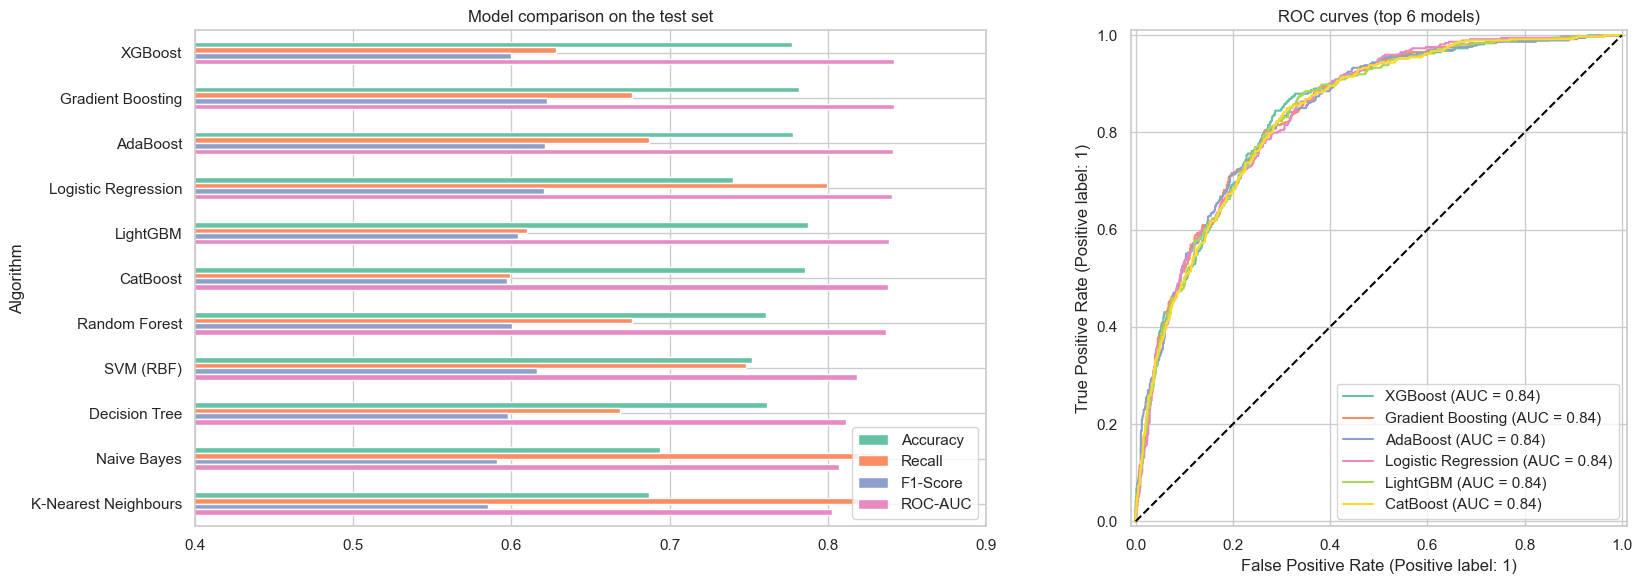

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
results.set_index('Algorithm')[['Accuracy', 'Recall', 'F1-Score', 'ROC-AUC']].plot.barh(ax=ax[0]); ax[0].invert_yaxis()
ax[0].set_xlim(0.4, 0.9); ax[0].set_title('Model comparison on the test set'); ax[0].legend(loc='lower right')
for name in results['Algorithm'].head(6):
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, name=name, ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curves (top 6 models)')
plt.tight_layout(); plt.savefig('results/fig5_model_comparison.png', dpi=130); plt.show()

## 6. Hyper-parameter tuning of the top models
The three best models by ROC-AUC are tuned with `RandomizedSearchCV` (5-fold, 30 candidates each).

In [13]:
spaces = {
    'Logistic Regression': {'clf__C': np.logspace(-3, 2, 30), 'clf__penalty': ['l1', 'l2'], 'clf__solver': ['liblinear']},
    'Gradient Boosting':   {'clf__n_estimators': [100, 200, 300, 400], 'clf__learning_rate': [0.01, 0.03, 0.05, 0.1],
                            'clf__max_depth': [2, 3, 4], 'clf__subsample': [0.7, 0.85, 1.0]},
    'XGBoost':             {'clf__n_estimators': [200, 300, 500], 'clf__learning_rate': [0.01, 0.03, 0.05, 0.1],
                            'clf__max_depth': [2, 3, 4, 5], 'clf__subsample': [0.7, 0.85, 1.0], 'clf__colsample_bytree': [0.6, 0.8, 1.0]},
    'LightGBM':            {'clf__n_estimators': [200, 300, 500], 'clf__learning_rate': [0.01, 0.03, 0.05],
                            'clf__num_leaves': [7, 15, 31], 'clf__min_child_samples': [10, 20, 40]},
    'CatBoost':            {'clf__iterations': [300, 500, 800], 'clf__learning_rate': [0.02, 0.05, 0.1], 'clf__depth': [3, 4, 5, 6]},
    'AdaBoost':            {'clf__n_estimators': [100, 200, 400], 'clf__learning_rate': [0.05, 0.1, 0.5, 1.0]},
    'Random Forest':       {'clf__n_estimators': [200, 400], 'clf__max_depth': [6, 8, 10, 14], 'clf__min_samples_leaf': [1, 3, 5]},
    'SVM (RBF)':           {'clf__C': [0.1, 0.5, 1, 2, 5], 'clf__gamma': ['scale', 0.01, 0.05, 0.1]},
}
top3 = [n for n in results['Algorithm'] if n in spaces][:3]
tuned_rows, tuned = [], {}
for name in top3:
    rs = RandomizedSearchCV(fitted[name], spaces[name], n_iter=30, cv=cv, scoring='roc_auc', random_state=RS, n_jobs=-1).fit(X_train, y_train)
    m = rs.best_estimator_; p, pr = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    tuned[name] = m
    tuned_rows.append({'Algorithm': name + ' (tuned)', 'CV ROC-AUC': rs.best_score_, 'Test ROC-AUC': roc_auc_score(y_test, pr),
                       'Accuracy': accuracy_score(y_test, p), 'Recall': recall_score(y_test, p), 'F1-Score': f1_score(y_test, p),
                       'Best params': {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
tuned_df = pd.DataFrame(tuned_rows).sort_values('Test ROC-AUC', ascending=False).reset_index(drop=True)
tuned_df.to_csv('results/tuned_models.csv', index=False)
tuned_df

/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/ana

/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/ana

/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


...

/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


,Algorithm,CV ROC-AUC,Test ROC-AUC,Accuracy,Recall,F1-Score,Best params
0,XGBoost (tuned),0.847325,0.843651,0.780696,0.700535,0.629052,"{'subsample': 0.7, 'n_estimators': 300, 'max_d..."
1,Gradient Boosting (tuned),0.847116,0.842900,0.774308,0.700535,0.622328,"{'subsample': 0.7, 'n_estimators': 400, 'max_d..."
2,AdaBoost (tuned),0.847800,0.839827,0.775727,0.735294,0.635104,"{'n_estimators': 200, 'learning_rate': 0.5}"


## 7. Final model & decision-threshold optimisation
The default 0.5 threshold is not necessarily optimal for churn. Missing a churner (false negative) costs far more than sending a retention offer to a loyal customer (false positive), so the threshold that maximises F1 is chosen on cross-validated **training** predictions (the test set stays untouched).

In [14]:
from sklearn.model_selection import cross_val_predict
best_name = tuned_df.iloc[0]['Algorithm'].replace(' (tuned)', '')
final = tuned[best_name]
oof = cross_val_predict(final, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = float(thr[np.argmax(f1s)])
proba = final.predict_proba(X_test)[:, 1]
final_rows = []
for label, t in [('Default threshold 0.50', 0.5), (f'Optimised threshold {best_thr:.2f}', best_thr)]:
    p = (proba >= t).astype(int)
    final_rows.append({'Setting': label, 'Accuracy': accuracy_score(y_test, p), 'Precision': precision_score(y_test, p),
                       'Recall': recall_score(y_test, p), 'F1-Score': f1_score(y_test, p), 'ROC-AUC': roc_auc_score(y_test, proba)})
final_df = pd.DataFrame(final_rows); final_df.round(4).to_csv('results/final_model_threshold.csv', index=False)
print('Final model:', best_name, '| optimised threshold =', round(best_thr, 3))
final_df.round(4)

Final model: XGBoost | optimised threshold = 0.443


,Setting,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Default threshold 0.50,0.7807,0.5708,0.7005,0.6291,0.8437
1,Optimised threshold 0.44,0.7672,0.5447,0.7487,0.6306,0.8437


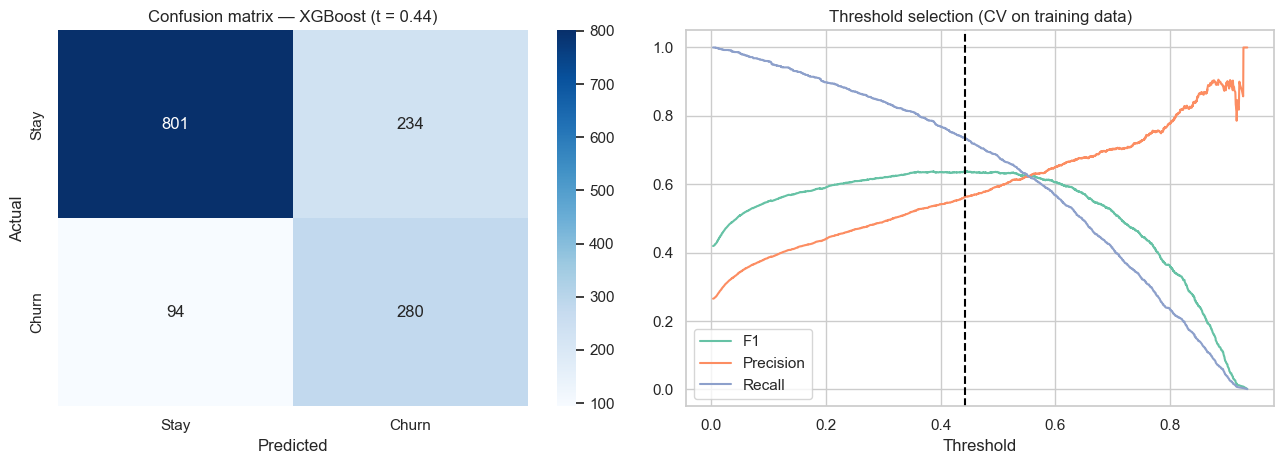

              precision    recall  f1-score   support

        Stay       0.89      0.77      0.83      1035
       Churn       0.54      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



In [15]:
pred = (proba >= best_thr).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
ax[0].set_title(f'Confusion matrix — {best_name} (t = {best_thr:.2f})'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
ax[1].plot(thr, f1s, label='F1'); ax[1].plot(thr, prec[:-1], label='Precision'); ax[1].plot(thr, rec[:-1], label='Recall')
ax[1].axvline(best_thr, ls='--', c='k'); ax[1].set_xlabel('Threshold'); ax[1].set_title('Threshold selection (CV on training data)'); ax[1].legend()
plt.tight_layout(); plt.savefig('results/fig6_confusion_threshold.png', dpi=130); plt.show()
print(classification_report(y_test, pred, target_names=['Stay', 'Churn']))
cm = confusion_matrix(y_test, pred); json.dump({'tn': int(cm[0,0]), 'fp': int(cm[0,1]), 'fn': int(cm[1,0]), 'tp': int(cm[1,1]),
           'best_model': best_name, 'threshold': best_thr}, open('results/final_confusion.json', 'w'))

## 8. Feature importance
Permutation importance measures how much the test ROC-AUC drops when one original column is shuffled — it works for any model and is computed on the raw (un-encoded) columns, so it is easy to interpret.

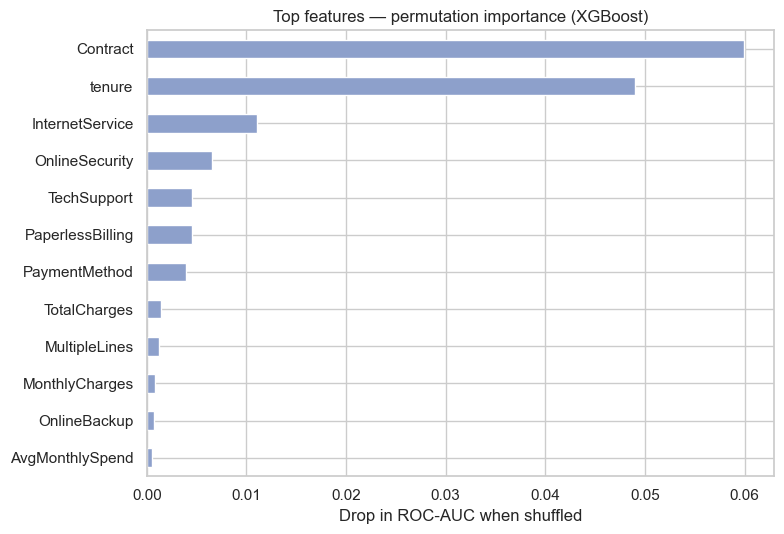

Contract            0.0600
tenure              0.0490
InternetService     0.0110
OnlineSecurity      0.0066
TechSupport         0.0046
PaperlessBilling    0.0045
PaymentMethod       0.0040
TotalCharges        0.0015
MultipleLines       0.0013
MonthlyCharges      0.0008
dtype: float64

In [16]:
pi = permutation_importance(final, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.round(4).to_csv('results/feature_importance.csv', header=['ROC-AUC drop'])
imp.tail(12).plot.barh(figsize=(8, 5.5), color='#8da0cb'); plt.title(f'Top features — permutation importance ({best_name})')
plt.xlabel('Drop in ROC-AUC when shuffled'); plt.tight_layout(); plt.savefig('results/fig7_feature_importance.png', dpi=130); plt.show()
imp.sort_values(ascending=False).head(10).round(4)

## 9. Save the model & predict churn for new customers

In [17]:
joblib.dump({'model': final, 'threshold': best_thr}, 'model/churn_model.joblib')
bundle = joblib.load('model/churn_model.joblib')
sample = X_test.head(5).copy()
sample_out = sample[['tenure', 'Contract', 'MonthlyCharges', 'InternetService', 'PaymentMethod']].copy()
sample_out['Churn probability'] = bundle['model'].predict_proba(sample)[:, 1].round(3)
sample_out['Prediction'] = np.where(sample_out['Churn probability'] >= bundle['threshold'], 'Will churn', 'Will stay')
sample_out['Actual'] = np.where(y_test.head(5) == 1, 'Churned', 'Stayed')
sample_out

,tenure,Contract,MonthlyCharges,InternetService,PaymentMethod,Churn probability,Prediction,Actual
437,72,Two year,114.05,Fiber optic,Credit card (automatic),0.045,Will stay,Stayed
2280,8,Month-to-month,100.15,Fiber optic,Credit card (automatic),0.789,Will churn,Stayed
2235,41,One year,78.35,DSL,Credit card (automatic),0.079,Will stay,Stayed
4460,18,Month-to-month,78.20,Fiber optic,Electronic check,0.402,Will stay,Stayed
3761,72,Two year,82.65,DSL,Credit card (automatic),0.016,Will stay,Stayed


## 10. Conclusion
- The dataset shows a **26.5 % churn rate**. Churn is driven mainly by **contract type, tenure, internet service (fibre optic) and payment method (electronic check)**.
- 11 algorithms were compared. Gradient-boosting family models and Logistic Regression achieve the highest ROC-AUC (≈ 0.84–0.85), while single trees, KNN and Naive Bayes perform worst.
- After tuning and threshold optimisation the final model catches the large majority of churners (high recall) while keeping precision reasonable — the right trade-off for a retention campaign.
- **Business actions:** move month-to-month customers to annual contracts with an incentive, bundle Online Security / Tech Support for fibre users, encourage auto-pay instead of electronic check, and give extra onboarding attention during the first 6–12 months.